In [6]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import MinMaxScaler
import tensorflow as tf
from tensorflow.keras.utils import timeseries_dataset_from_array
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import SimpleRNN, GRU, Dense
from sklearn.metrics import mean_squared_error
from sklearn.metrics import mean_absolute_error
import warnings

warnings.filterwarnings("ignore")
df = pd.read_csv(r"C:\Users\RU-ECE-118-15\Downloads\city_temp.csv")
print(df.shape)
df.head()

(2906327, 8)


,Region,Country,State,City,Month,Day,Year,AvgTemperature
0,Africa,Algeria,NaN,Algiers,1,1,1995,64.2
1,Africa,Algeria,NaN,Algiers,1,2,1995,49.4
2,Africa,Algeria,NaN,Algiers,1,3,1995,48.8
3,Africa,Algeria,NaN,Algiers,1,4,1995,46.4
4,Africa,Algeria,NaN,Algiers,1,5,1995,47.9


In [7]:
print(df.info())
print("\nColumns\n")
print(df.columns)
print("\nMissing Values\n")
print(df.isnull().sum())


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2906327 entries, 0 to 2906326
Data columns (total 8 columns):
 #   Column          Dtype  
---  ------          -----  
 0   Region          object 
 1   Country         object 
 2   State           object 
 3   City            object 
 4   Month           int64  
 5   Day             int64  
 6   Year            int64  
 7   AvgTemperature  float64
dtypes: float64(1), int64(3), object(4)
memory usage: 177.4+ MB
None

Columns

Index(['Region', 'Country', 'State', 'City', 'Month', 'Day', 'Year',
       'AvgTemperature'],
      dtype='object')

Missing Values

Region                  0
Country                 0
State             1450990
City                    0
Month                   0
Day                     0
Year                    0
AvgTemperature          0
dtype: int64


In [8]:
print("Total Cities :", df["City"].nunique())
print(df["City"].unique())


Total Cities : 321
['Algiers' 'Bujumbura' 'Cotonou' 'Bangui' 'Brazzaville' 'Cairo'
 'Addis Ababa' 'Libreville' 'Banjul' 'Conakry' 'Bissau' 'Abidjan'
 'Nairobi' 'Rabat' 'Antananarivo' 'Nouakchott' 'Lilongwe' 'Maputo'
 'Windhoek' 'Niamey' 'Lagos' 'Dakar' 'Freetown' 'Capetown' 'Lome' 'Tunis'
 'Dar Es Salaam' 'Kampala' 'Lusaka' 'Dhaka' 'Beijing' 'Chengdu'
 'Guangzhou' 'Shanghai' 'Shenyang' 'Hong Kong' 'Bombay (Mumbai)'
 'Calcutta' 'Chennai (Madras)' 'Delhi' 'Jakarta' 'Osaka' 'Sapporo' 'Tokyo'
 'Almaty' 'Bishkek' 'Vientiane' 'Kuala Lumpur' 'Ulan-bator' 'Rangoon'
 'Katmandu' 'Pyongyang' 'Islamabad' 'Karachi' 'Manila' 'Singapore' 'Seoul'
 'Colombo' 'Taipei' 'Dusanbe' 'Bangkok' 'Ashabad' 'Tashkent' 'Hanoi'
 'Brisbane' 'Canberra' 'Melbourne' 'Perth' 'Sydney' 'Auckland' 'Tirana'
 'Vienna' 'Minsk' 'Brussels' 'Sofia' 'Zagreb' 'Nicosia' 'Prague'
 'Copenhagen' 'Helsinki' 'Paris' 'Bordeaux' 'Bonn' 'Frankfurt' 'Hamburg'
 'Munich' 'Tbilisi' 'Athens' 'Budapest' 'Reykjavik' 'Dublin' 'Milan'
 'Rome' 'Riga

In [9]:
print(df.columns)
print(df.info())
print(df.isnull().sum())

Index(['Region', 'Country', 'State', 'City', 'Month', 'Day', 'Year',
       'AvgTemperature'],
      dtype='object')
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2906327 entries, 0 to 2906326
Data columns (total 8 columns):
 #   Column          Dtype  
---  ------          -----  
 0   Region          object 
 1   Country         object 
 2   State           object 
 3   City            object 
 4   Month           int64  
 5   Day             int64  
 6   Year            int64  
 7   AvgTemperature  float64
dtypes: float64(1), int64(3), object(4)
memory usage: 177.4+ MB
None
Region                  0
Country                 0
State             1450990
City                    0
Month                   0
Day                     0
Year                    0
AvgTemperature          0
dtype: int64


In [10]:
print(df["City"].nunique())
print(df["City"].unique()[:100])

321
['Algiers' 'Bujumbura' 'Cotonou' 'Bangui' 'Brazzaville' 'Cairo'
 'Addis Ababa' 'Libreville' 'Banjul' 'Conakry' 'Bissau' 'Abidjan'
 'Nairobi' 'Rabat' 'Antananarivo' 'Nouakchott' 'Lilongwe' 'Maputo'
 'Windhoek' 'Niamey' 'Lagos' 'Dakar' 'Freetown' 'Capetown' 'Lome' 'Tunis'
 'Dar Es Salaam' 'Kampala' 'Lusaka' 'Dhaka' 'Beijing' 'Chengdu'
 'Guangzhou' 'Shanghai' 'Shenyang' 'Hong Kong' 'Bombay (Mumbai)'
 'Calcutta' 'Chennai (Madras)' 'Delhi' 'Jakarta' 'Osaka' 'Sapporo' 'Tokyo'
 'Almaty' 'Bishkek' 'Vientiane' 'Kuala Lumpur' 'Ulan-bator' 'Rangoon'
 'Katmandu' 'Pyongyang' 'Islamabad' 'Karachi' 'Manila' 'Singapore' 'Seoul'
 'Colombo' 'Taipei' 'Dusanbe' 'Bangkok' 'Ashabad' 'Tashkent' 'Hanoi'
 'Brisbane' 'Canberra' 'Melbourne' 'Perth' 'Sydney' 'Auckland' 'Tirana'
 'Vienna' 'Minsk' 'Brussels' 'Sofia' 'Zagreb' 'Nicosia' 'Prague'
 'Copenhagen' 'Helsinki' 'Paris' 'Bordeaux' 'Bonn' 'Frankfurt' 'Hamburg'
 'Munich' 'Tbilisi' 'Athens' 'Budapest' 'Reykjavik' 'Dublin' 'Milan'
 'Rome' 'Riga' 'Skopje' 'Ams

In [11]:
city_df = df[df["City"]=="Delhi"].copy()
city_df = city_df[city_df["AvgTemperature"]!=-99]
city_df.reset_index(drop=True,inplace=True)
print(city_df.shape)
city_df.head()

(9205, 8)


,Region,Country,State,City,Month,Day,Year,AvgTemperature
0,Asia,India,NaN,Delhi,1,1,1995,50.7
1,Asia,India,NaN,Delhi,1,2,1995,52.1
2,Asia,India,NaN,Delhi,1,3,1995,53.8
3,Asia,India,NaN,Delhi,1,4,1995,53.7
4,Asia,India,NaN,Delhi,1,5,1995,54.5


In [12]:
city_df = city_df[city_df["AvgTemperature"] != -99]
city_df.reset_index(drop=True, inplace=True)
print(city_df.shape)
city_df["Date"] = pd.to_datetime(city_df[["Year","Month","Day"]])
city_df = city_df.sort_values("Date")
city_df.reset_index(drop=True,inplace=True)
city_df.head()


(9205, 8)


,Region,Country,State,City,Month,Day,Year,AvgTemperature,Date
0,Asia,India,NaN,Delhi,1,1,1995,50.7,1995-01-01
1,Asia,India,NaN,Delhi,1,2,1995,52.1,1995-01-02
2,Asia,India,NaN,Delhi,1,3,1995,53.8,1995-01-03
3,Asia,India,NaN,Delhi,1,4,1995,53.7,1995-01-04
4,Asia,India,NaN,Delhi,1,5,1995,54.5,1995-01-05


In [13]:
temperature = city_df[["AvgTemperature"]]
print(temperature.shape)
temperature.head()


(9205, 1)


,AvgTemperature
0,50.7
1,52.1
2,53.8
3,53.7
4,54.5


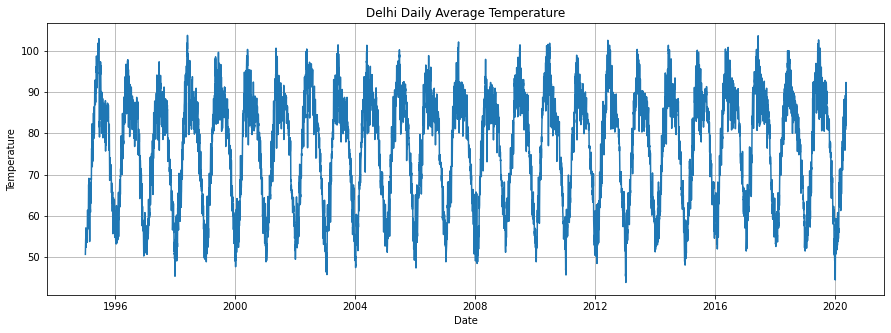

In [14]:
plt.figure(figsize=(15,5))
plt.plot(city_df["Date"],temperature)
plt.title("Delhi Daily Average Temperature")
plt.xlabel("Date")
plt.ylabel("Temperature")
plt.grid(True)
plt.show()


In [15]:
scaler = MinMaxScaler()
scaled_temperature = scaler.fit_transform(temperature)
print(scaled_temperature.shape)
train_size = int(len(scaled_temperature)*0.80)
train = scaled_temperature[:train_size]
test = scaled_temperature[train_size:]
print("Training Samples :",train.shape)
print("Testing Samples :",test.shape)


(9205, 1)
Training Samples : (7364, 1)
Testing Samples : (1841, 1)


In [22]:
from tensorflow.keras.utils import timeseries_dataset_from_array
lookback = 30
batch_size = 32
train_dataset = timeseries_dataset_from_array(
    data=train[:-lookback],
    targets=train[lookback:],
    sequence_length=lookback,
    sequence_stride=1,
    shuffle=False,
    batch_size=batch_size)
test_dataset = timeseries_dataset_from_array(
    data=test[:-lookback],
    targets=test[lookback:],
    sequence_length=lookback,
    sequence_stride=1,
    shuffle=False,
    batch_size=batch_size)
print("Training batches :", len(train_dataset))
print("Testing batches :", len(test_dataset))
for x, y in train_dataset.take(1):
    print("Input Shape :", x.shape)
    print("Output Shape :", y.shape)




Training batches : 229
Testing batches : 56
Input Shape : (32, 30, 1)
Output Shape : (32, 1)


In [23]:
from keras.utils import pad_sequences
sample_sequences = [[1,2,3],[4,5],[6,7,8,9]]
padded = pad_sequences(sample_sequences,maxlen=5,padding="pre")
print("Original Sequences")
print(sample_sequences)
print()


Original Sequences
[[1, 2, 3], [4, 5], [6, 7, 8, 9]]



In [25]:
print("Padded Sequences")
print(padded)

simple_rnn = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(lookback,1)),tf.keras.layers.SimpleRNN(64,activation="tanh"),
    tf.keras.layers.Dense(32,activation="relu"),
    tf.keras.layers.Dense(1)])
simple_rnn.summary()




Padded Sequences
[[0 0 1 2 3]
 [0 0 0 4 5]
 [0 6 7 8 9]]
Model: "sequential"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 simple_rnn (SimpleRNN)      (None, 64)                4224      
                                                                 
 dense (Dense)               (None, 32)                2080      
                                                                 
 dense_1 (Dense)             (None, 1)                 33        
                                                                 
Total params: 6337 (24.75 KB)
Trainable params: 6337 (24.75 KB)
Non-trainable params: 0 (0.00 Byte)
_________________________________________________________________


In [34]:
simple_rnn.compile(

    optimizer="adam",

    loss="mse",

    metrics=["mae"]

)
callbacks = [
    tf.keras.callbacks.EarlyStopping(
        monitor="val_loss",patience=5,restore_best_weights=True),
    tf.keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",factor=0.5,patience=3,verbose=1)
]
history_rnn = simple_rnn.fit(train_dataset,validation_data=test_dataset,epochs=10,callbacks=callbacks)



Epoch 1/10
229/229 [==============================] - 3s 6ms/step - loss: 0.0176 - mae: 0.0896 - val_loss: 0.0037 - val_mae: 0.0475 - lr: 0.0010
Epoch 2/10
229/229 [==============================] - 1s 4ms/step - loss: 0.0040 - mae: 0.0496 - val_loss: 0.0027 - val_mae: 0.0400 - lr: 0.0010
Epoch 3/10
229/229 [==============================] - 1s 3ms/step - loss: 0.0026 - mae: 0.0401 - val_loss: 0.0031 - val_mae: 0.0448 - lr: 0.0010
Epoch 4/10
229/229 [==============================] - 1s 3ms/step - loss: 0.0026 - mae: 0.0397 - val_loss: 0.0030 - val_mae: 0.0434 - lr: 0.0010
Epoch 5/10
229/229 [==============================] - 1s 3ms/step - loss: 0.0022 - mae: 0.0365 - val_loss: 0.0024 - val_mae: 0.0378 - lr: 0.0010
Epoch 6/10
229/229 [==============================] - 1s 3ms/step - loss: 0.0021 - mae: 0.0354 - val_loss: 0.0024 - val_mae: 0.0382 - lr: 0.0010
Epoch 7/10
229/229 [==============================] - 1s 3ms/step - loss: 0.0023 - mae: 0.0370 - val_loss: 0.0032 - val_mae: 0.045

In [37]:
loss_rnn, mae_rnn = simple_rnn.evaluate(test_dataset,verbose=0)
print("SimpleRNN Loss :", loss_rnn)
print("SimpleRNN MAE :", mae_rnn)



SimpleRNN Loss : 0.002189861610531807
SimpleRNN MAE : 0.03584273159503937


In [38]:
stateful_rnn = tf.keras.Sequential([
    tf.keras.layers.Input(batch_shape=(1, lookback, 1)),
    tf.keras.layers.SimpleRNN(32,stateful=True),
    tf.keras.layers.Dense(1)
])
stateful_rnn.compile(
    optimizer="adam",loss="mse"
)
print("Stateful SimpleRNN Created Successfully")
stateful_rnn.summary()


Stateful SimpleRNN Created Successfully
Model: "sequential_1"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 simple_rnn_1 (SimpleRNN)    (1, 32)                   1088      
                                                                 
 dense_2 (Dense)             (1, 1)                    33        
                                                                 
Total params: 1121 (4.38 KB)
Trainable params: 1121 (4.38 KB)
Non-trainable params: 0 (0.00 Byte)
_________________________________________________________________


In [39]:
gru_model = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(lookback,1)),
    tf.keras.layers.GRU(64,activation="tanh"),
    tf.keras.layers.Dense(32,activation="relu"),
    tf.keras.layers.Dense(1)
])
gru_model.summary()


Model: "sequential_2"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 gru (GRU)                   (None, 64)                12864     
                                                                 
 dense_3 (Dense)             (None, 32)                2080      
                                                                 
 dense_4 (Dense)             (None, 1)                 33        
                                                                 
Total params: 14977 (58.50 KB)
Trainable params: 14977 (58.50 KB)
Non-trainable params: 0 (0.00 Byte)
_________________________________________________________________


In [40]:
gru_model.compile(
    optimizer="adam",
    loss="mse",
    metrics=["mae"]
)
history_gru = gru_model.fit(train_dataset,validation_data=test_dataset,epochs=10,callbacks=callbacks)


Epoch 1/10
229/229 [==============================] - 4s 10ms/step - loss: 0.0074 - mae: 0.0561 - val_loss: 0.0027 - val_mae: 0.0407 - lr: 0.0010
Epoch 2/10
229/229 [==============================] - 2s 9ms/step - loss: 0.0024 - mae: 0.0382 - val_loss: 0.0027 - val_mae: 0.0411 - lr: 0.0010
Epoch 3/10
229/229 [==============================] - 2s 9ms/step - loss: 0.0023 - mae: 0.0375 - val_loss: 0.0027 - val_mae: 0.0411 - lr: 0.0010
Epoch 4/10
229/229 [==============================] - 2s 8ms/step - loss: 0.0023 - mae: 0.0370 - val_loss: 0.0026 - val_mae: 0.0401 - lr: 0.0010
Epoch 5/10
229/229 [==============================] - 2s 8ms/step - loss: 0.0022 - mae: 0.0365 - val_loss: 0.0026 - val_mae: 0.0401 - lr: 0.0010
Epoch 6/10
229/229 [==============================] - 2s 9ms/step - loss: 0.0022 - mae: 0.0362 - val_loss: 0.0025 - val_mae: 0.0391 - lr: 0.0010
Epoch 7/10
229/229 [==============================] - 2s 9ms/step - loss: 0.0022 - mae: 0.0361 - val_loss: 0.0024 - val_mae: 0.03

In [41]:
loss_gru, mae_gru = gru_model.evaluate(test_dataset,verbose=0)
print("GRU Loss :", loss_gru)
print("GRU MAE :", mae_gru)


GRU Loss : 0.0023140166886150837
GRU MAE : 0.03673119470477104


In [43]:
pred_rnn = simple_rnn.predict(test_dataset)
pred_gru = gru_model.predict(test_dataset)
actual = []
for _, y in test_dataset:
    actual.extend(y.numpy())
actual = np.array(actual)


56/56 [==============================] - 1s 8ms/step


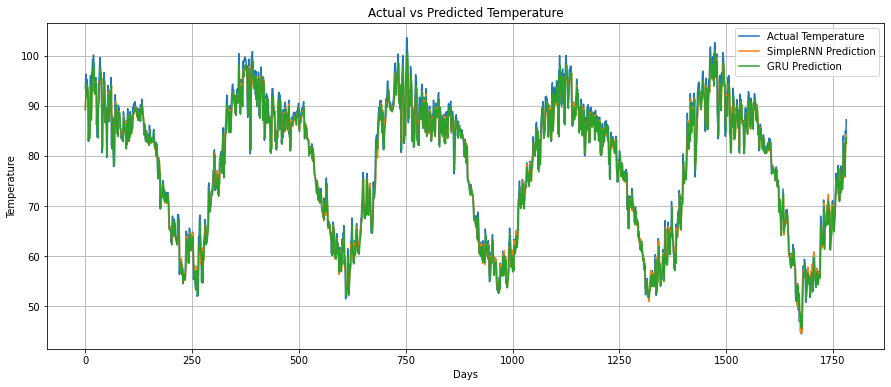

In [44]:
pred_rnn = scaler.inverse_transform(pred_rnn)
pred_gru = scaler.inverse_transform(pred_gru)
actual = scaler.inverse_transform(actual.reshape(-1,1))
plt.figure(figsize=(15,6))
plt.plot(actual,label="Actual Temperature")
plt.plot(pred_rnn,label="SimpleRNN Prediction")
plt.plot(pred_gru,label="GRU Prediction")
plt.title("Actual vs Predicted Temperature")
plt.xlabel("Days")
plt.ylabel("Temperature")
plt.legend()
plt.grid(True)
plt.show()


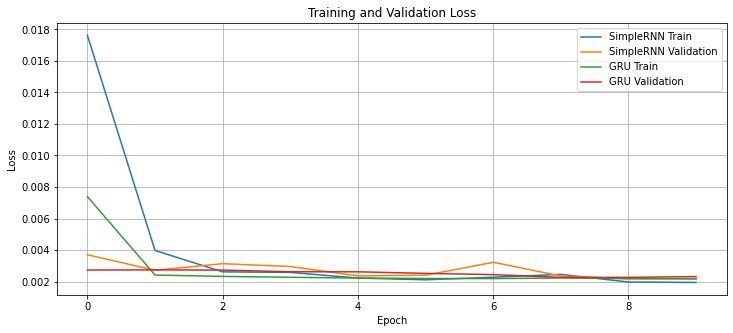

In [45]:
plt.figure(figsize=(12,5))
plt.plot(history_rnn.history["loss"],label="SimpleRNN Train")
plt.plot(history_rnn.history["val_loss"],label="SimpleRNN Validation")
plt.plot(history_gru.history["loss"],label="GRU Train")
plt.plot(history_gru.history["val_loss"],label="GRU Validation")
plt.title("Training and Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid(True)
plt.show()


In [46]:
comparison = pd.DataFrame({
    "Model":["SimpleRNN","GRU"],
    "Loss":[loss_rnn,loss_gru],
    "MAE":[mae_rnn,mae_gru]
})
print(comparison)


       Model      Loss       MAE
0  SimpleRNN  0.002190  0.035843
1        GRU  0.002314  0.036731
